<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

# Unsupervised learning exercise: Clustering load profiles of different users

</div>

**Objective:** You work at a distribution system operator (DSO). Smart meters give you the hourly net load of every building, but not always which buildings have rooftop PV, an electric vehicle (EV) or a heat pump (HP): PV is usually registered, EVs and heat pumps often are not, and all three change how the grid is loaded. Can you find them from the load alone?

The dataset has 700 Belgian meters (2024) in four groups of 175: `Nothing`, `PV`, `EV_PV` (EV + PV) and `EV_HP` (EV + heat pump, no PV). The labels are never used to build the clusters; we use them only afterwards, to measure how well each clustering recovers them. The exercise follows Canaydin, Depoortere & Kazmi (ISGT Europe 2024), *Feature-based identification of DERs in buildings from aggregated smart meter data* (PDF in the course folder).

| Part | How | Time |
|---|---|---|
| 0. Load and explore the data | together, fill the blanks | 10 min |
| 1. Clustering the average daily profiles | you, then solution | 15 min |
| 2. Comparing curves with Dynamic Time Warping (DTW) | together, fill the blanks | 10 min |
| 3. Clustering statistical features | you (fill the blanks), then solution | 15 min |
| 4. Choosing k and interpreting the clusters | you, then solution | 10 min |
| 5. Another model: Gaussian Mixture (GMM) | together, fill the blanks | 10 min |
| 6. Visualisation: PCA and t-SNE | PCA: you, then solution; t-SNE: together | 15 min |
| 7. Conclusions | together | 5 min |

The data is stored as Parquet (22 MB, a random sample of 175 meters per class from the original 1,200). Reading it needs `pyarrow`, and Section 2 needs `tslearn`: if the first code cell fails, run `pip install pyarrow tslearn`.

Answer the ✏️ questions in the cell below each one.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 0. Load and explore the data

</div>

*Together: fill in the blanks as we go.*

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score, f1_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
warnings.filterwarnings('ignore', message='h5py not installed')   # tslearn's optional HDF5 support, not used here
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import dtw

sns.set(style="whitegrid")

df_raw = pd.read_parquet('Data/sm_hourly_profiles_belgium_700.parquet')
df_raw

,SM_ID,Label,Start_Date,SM_kWh
0,SM_001,EV_PV,2024-01-01 00:00:00,0.293
1,SM_001,EV_PV,2024-01-01 01:00:00,0.245
2,SM_001,EV_PV,2024-01-01 02:00:00,0.285
3,SM_001,EV_PV,2024-01-01 03:00:00,0.246
4,SM_001,EV_PV,2024-01-01 04:00:00,0.257
...,...,...,...,...
6148095,SM_700,EV_PV,2024-12-31 19:00:00,0.733
6148096,SM_700,EV_PV,2024-12-31 20:00:00,0.771
6148097,SM_700,EV_PV,2024-12-31 21:00:00,0.623
6148098,SM_700,EV_PV,2024-12-31 22:00:00,0.789


**What do the columns mean?**

* **[SM_ID]**: smart meter ID (SM_001 to SM_700)
* **[Label]**: installed DERs (hidden during clustering)
* **[Start_Date]**: start of the hour, Belgian local time (CET/CEST). On 31 March 02:00 does not exist (clock change), so each meter has 8,783 hours instead of 8,784.
* **[SM_kWh]**: net energy in the hour [kWh] (= average power in kW). **Negative = export** to the grid (PV).

In [2]:
print(df_raw.shape)
print(df_raw.drop_duplicates('SM_ID')['Label'].value_counts())
df_raw.describe()

(6148100, 4)


Label
EV_PV      175
PV         175
Nothing    175
EV_HP      175
Name: count, dtype: int64


,Start_Date,SM_kWh
count,6148100,6.148100e+06
mean,2024-07-01 23:45:13.833539,3.736371e-01
min,2024-01-01 00:00:00,-8.145000e+00
25%,2024-04-01 12:00:00,6.500000e-02
50%,2024-07-02 00:00:00,1.840000e-01
75%,2024-10-01 12:00:00,4.410000e-01
max,2024-12-31 23:00:00,2.285000e+01
std,NaN,1.165509e+00


✏️ **Q0.** (1) How many rows does the table have, and how many hours does that make per meter? (2) How many meters are there per class? (3) What range does `SM_kWh` cover, what does a negative value mean, and why is the median so far below the mean?

**Answer:** 6,148,100 rows = 700 meters × 8,783 hours (2024 has 8,784 hours, minus the one skipped on 31 March), and 175 meters per class. `SM_kWh` goes from −8.1 kWh to 22.9 kWh: negative values are export to the grid, so only PV buildings can have them. The median (0.18 kWh) is half the mean (0.37 kWh) because a minority of large consumers pulls the mean up.

Before clustering, look at what we are trying to recover. The plot below uses the labels, which is fine for exploration: it shows the differences a good clustering would have to pick up. Each class is averaged by hour of the day and season, as in Fig. 1 of the paper. First add three helper columns: the hour of the day, the month, and the season (winter = December to February, summer = June to August, the rest spring/autumn).

In [3]:
df_raw['hour'] = df_raw['Start_Date'].dt.hour
df_raw['month'] = df_raw['Start_Date'].dt.month
df_raw['season'] = np.where(df_raw['month'].isin([12, 1, 2]), 'Winter',
                   np.where(df_raw['month'].isin([6, 7, 8]), 'Summer', 'Spring/Autumn'))

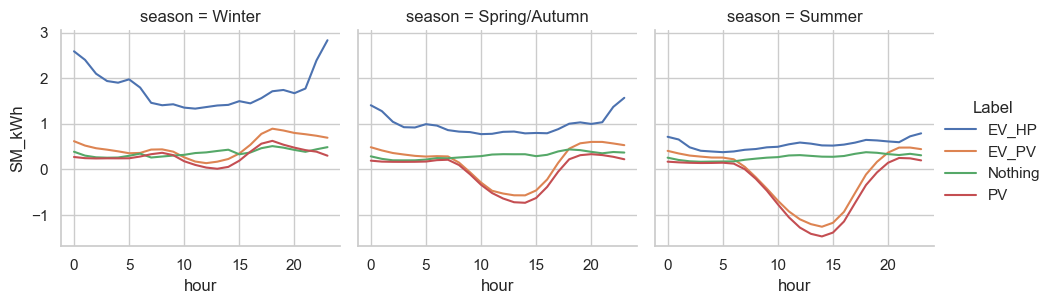

In [4]:
# Mean net load of each class at each hour, per season: the curves a good clustering should tell apart
profile = df_raw.groupby(['season', 'Label', 'hour'])['SM_kWh'].mean().reset_index()
# One panel per season, one line per class (labels used for exploration only, never for clustering)
sns.relplot(data=profile, x='hour', y='SM_kWh', hue='Label', col='season',
            col_order=['Winter', 'Spring/Autumn', 'Summer'], kind='line', height=3.2)
plt.show()

> **Reading the plot:** PV is the strongest signature: the net load of `PV` and `EV_PV` goes negative around midday, down to about −1.5 kWh in summer but barely to zero in winter. `EV_HP` is the largest consumer all year, highest in winter (heat pump) and peaking around midnight (night charging). `PV` and `EV_PV` have the same shape and differ mostly in the evening and at night, when the EV is charged: expect the clustering to confuse these two.

In [5]:
# From now on we only use the load. The labels are kept aside, aligned by SM_ID, to validate the clusters.
df_sm = df_raw[['SM_ID', 'hour', 'SM_kWh']]
labels = df_raw.groupby('SM_ID')['Label'].first()   # one label per meter, sorted by SM_ID
labels.head()

SM_ID
SM_001    EV_PV
SM_002       PV
SM_003    EV_PV
SM_004       PV
SM_005       PV
Name: Label, dtype: str

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 1. Clustering the average daily profiles

</div>

*You write the code; then we go over the solution together.*

The slide *Clustering time series* gave two options for curves like these: cluster the raw values, or derive features first. We start with the raw values. Each meter becomes its average daily profile, 24 numbers: the mean net load at 0 h, 1 h, …, 23 h over the whole year. Averaging 366 days removes day-to-day noise, but also the seasons: the heat pump's winter load and the deep summer PV dip are blended into one curve.

In [6]:
# Build df_profiles: one row per meter (SM_ID), one column per hour (0-23), values = mean SM_kWh over the year.
# Hint: group df_sm by ['SM_ID', 'hour'], take the mean of 'SM_kWh', then .unstack().
df_profiles = df_sm.groupby(['SM_ID', 'hour'])['SM_kWh'].mean().unstack()
df_profiles

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
SM_ID,,,,,,,,,,,,,,,,,,,,,
SM_001,0.291899,0.289959,0.290649,0.290057,0.290003,0.294208,0.351273,0.422751,0.342262,0.078923,...,-0.465719,-0.263579,-0.046393,0.303260,0.527243,0.495063,0.562555,0.636027,0.503180,0.306844
SM_002,0.178814,0.165393,0.163252,0.161309,0.179096,0.165689,0.164022,0.074918,-0.171270,-0.347260,...,-0.570178,-0.383730,-0.060740,0.223178,0.386418,0.412989,0.438522,0.383708,0.306235,0.231768
SM_003,0.657219,0.635109,0.552742,0.502014,0.426743,0.316544,0.284505,0.399683,0.329131,0.236546,...,-0.888511,-0.648000,-0.203511,0.214899,0.572191,0.725434,0.731352,0.702391,0.670115,0.629333
SM_004,0.207131,0.173628,0.175882,0.174314,0.172762,0.171205,0.120352,0.034361,-0.035817,-0.204440,...,-0.982022,-0.892762,-0.754068,-0.480221,0.175489,0.459232,0.412451,0.560404,0.536481,0.372675
SM_005,0.058697,0.060762,0.051025,0.053169,0.062180,0.058530,0.115809,0.158500,0.084172,-0.063590,...,-0.726519,-0.692123,-0.547702,-0.264380,0.011697,0.055770,0.154219,0.167295,0.130074,0.069995
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SM_696,0.104806,0.105883,0.109770,0.119057,0.127615,0.133836,0.176210,0.392148,0.277975,0.189612,...,-0.137508,-0.125057,-0.038743,0.063880,0.141495,0.173536,0.167317,0.147451,0.135036,0.106489
SM_697,1.395929,2.367238,1.337775,1.177322,0.659238,0.945929,1.401467,0.416809,0.392699,0.442071,...,0.430762,3.795702,1.423317,0.634754,0.833388,0.984697,0.931025,0.765784,0.887227,2.526150
SM_698,0.509276,0.407781,0.332000,0.278202,0.267303,0.253066,0.203156,0.016784,-0.412555,-1.008811,...,-1.848038,-1.536801,-1.113016,-0.456142,0.190145,0.595243,0.893328,0.864158,0.746107,0.642760


All 24 columns share a unit (kWh), so standardising them is optional. We leave them as they are, so that the hours in which meters differ most (around midnight and midday) weigh more in the distance than the quieter morning hours. We set k = 4 because we know there are four classes; Section 4 asks what you would do without that knowledge.

**Comparing clusters with labels: the Adjusted Rand Index (ARI).** Accuracy or F1 would need each cluster to be matched to a class first, and cluster numbers are arbitrary. The ARI compares the two groupings directly, through pairs of meters: a pair is an agreement when the clustering and the labels both put the two meters together, or both keep them apart. The share of agreeing pairs is the Rand index (RI), which is misleading on its own: with four groups of 175, a random clustering already agrees on about 62 % of pairs, because most pairs are apart in both. The ARI rescales it so that chance gives 0:

$$\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]}$$

$\mathbb{E}[\text{RI}]$ is the RI expected from a random clustering with the same cluster sizes (≈ 0.62 here) and $\max(\text{RI})$ its best possible value. ARI = 1 means identical groupings, ≈ 0 means no better than chance, and it can be slightly negative. Since it only uses the crosstab, the numbering of the clusters does not matter.

The ARI has no counterpart in classification, so we also report a more familiar view. Name each cluster after the label carried by most of its meters, and the clustering becomes a classifier that can be scored with accuracy and macro-F1. Two clusters may get the same name; the class left without a cluster then has no correct predictions, which macro-F1 penalises and accuracy hides. The naming uses the labels, so this is an evaluation step only, not something a DSO could do.

In [7]:
# Run KMeans(n_clusters=4, n_init=10, random_state=0) on df_profiles and store the fitted model in km_raw.
# Print the ARI (adjusted_rand_score), the accuracy and the macro-F1, and show pd.crosstab(labels, km_raw.labels_).
# To name each cluster after its majority label: pred = pd.crosstab(labels, km_raw.labels_).idxmax().loc[km_raw.labels_].values
km_raw = KMeans(n_clusters=4, n_init=10, random_state=0).fit(df_profiles)
pred = pd.crosstab(labels, km_raw.labels_).idxmax().loc[km_raw.labels_].values
print('ARI raw profiles:', round(adjusted_rand_score(labels, km_raw.labels_), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, km_raw.labels_)

ARI raw profiles: 0.352
Accuracy: 0.631 | macro-F1: 0.548


col_0,0,1,2,3
Label,,,,
EV_HP,51,94,0,30
EV_PV,59,2,114,0
Nothing,169,2,0,4
PV,26,0,149,0


Look at where `EV_HP` ends up in the crosstab. Euclidean distance on raw kWh is dominated by how much a meter consumes, and `EV_HP` meters range from moderate to very large. To compare *shapes* instead, rescale each meter's profile (each row) to mean 0 and standard deviation 1.

In [8]:
# Normalise each row of df_profiles (z-score per meter) into df_shape, run k-means (k=4, n_init=10, random_state=0) into km_shape,
# and print the ARI, accuracy, macro-F1 and the crosstab, as above.
# Hint: df_profiles.sub(df_profiles.mean(axis=1), axis=0) subtracts each row's mean; .div(df_profiles.std(axis=1), axis=0) divides by each row's std.
# (StandardScaler would scale each column, i.e. each hour, which is not what we want here.)
df_shape = df_profiles.sub(df_profiles.mean(axis=1), axis=0).div(df_profiles.std(axis=1), axis=0)

km_shape = KMeans(n_clusters=4, n_init=10, random_state=0).fit(df_shape)
pred = pd.crosstab(labels, km_shape.labels_).idxmax().loc[km_shape.labels_].values
print('ARI normalised profiles:', round(adjusted_rand_score(labels, km_shape.labels_), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, km_shape.labels_)

ARI normalised profiles: 0.342
Accuracy: 0.621 | macro-F1: 0.616


col_0,0,1,2,3
Label,,,,
EV_HP,16,86,13,60
EV_PV,54,8,106,7
Nothing,2,14,4,155
PV,88,0,86,1


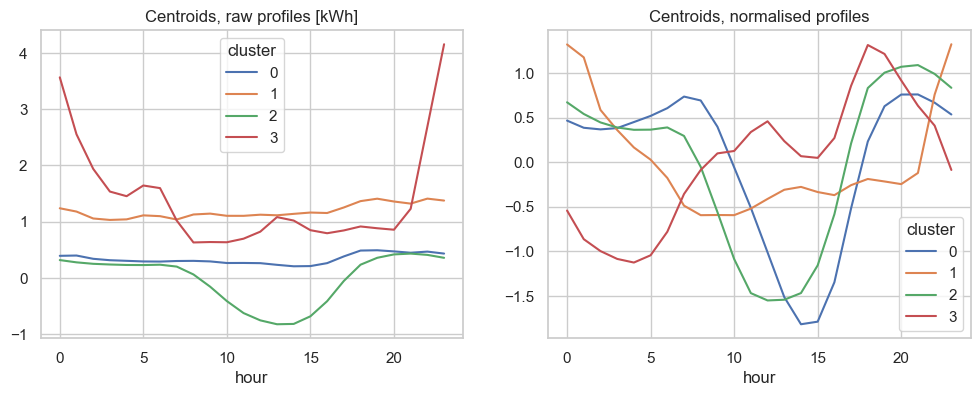

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_raw.cluster_centers_.T)
axes[0].set_title('Centroids, raw profiles [kWh]')
axes[1].plot(km_shape.cluster_centers_.T)
axes[1].set_title('Centroids, normalised profiles')
for ax in axes:
    ax.set_xlabel('hour'); ax.legend(range(4), title='cluster')
plt.show()

✏️ **Q1.** Name the four raw-profile clusters from their centroids. Normalising was meant to remove the size effect, yet the ARI went down: what information did it throw away, and which classes does that mix up?

**Answer:** Raw centroids: a midday dip (`PV` and `EV_PV` together), a small flat profile (mostly `Nothing`), and two large consumers, one flat around 1 kWh and one with a strong night peak (both mostly `EV_HP`, split by size). Normalising lowers the ARI slightly (0.35 → 0.34) because size was carrying information: after z-scoring, a flat 0.3 kWh profile and a flat 1 kWh profile look the same, so one cluster now holds 155 `Nothing` and 60 `EV_HP` meters. Macro-F1 moves the other way (0.55 → 0.62): the raw clustering gives `EV_PV` no cluster of its own and the normalised one does, so the two metrics disagree on which is better.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 2. Comparing curves with Dynamic Time Warping (DTW)

</div>

*Together: fill in the blanks as we go.*

The clustering of Section 1 used the Euclidean distance, which compares two curves hour by hour. Two homes that charge the same EV for 1 hour at 21 h and at 23 h then look as different as a home with an EV and one without (or even more). DTW first aligns the two curves: each hour of one profile may be matched with a nearby hour of the other, and the distance is summed along the best alignment, the *warping path*. Without a limit, the alignment can stretch a curve so far that a midnight peak is matched with the midday PV dip; a window of ±2 h (the Sakoe–Chiba band) keeps the matching physically plausible.

<img src="Figures/dtw_vs_euc.svg" width="900">

On the left, the Euclidean distance matches each time step with the same time step of the other curve, so two curves with the same shape, shifted in time, end up far apart. On the right, DTW matches each point with its best counterpart nearby: the grey lines lean, and the two bumps are matched with each other. The same in numbers, for two identical evening peaks two hours apart:

In [10]:
hours = np.arange(24)
peak_19 = np.exp(-(hours - 19) ** 2 / 2)   # evening peak at 19 h
peak_21 = np.exp(-(hours - 21) ** 2 / 2)   # the same peak two hours later

print('Euclidean distance:', round(np.linalg.norm(peak_19 - peak_21), 2))
print('DTW distance, window ±2 h:', round(dtw(peak_19, peak_21, global_constraint='sakoe_chiba', sakoe_chiba_radius=2), 2))

Euclidean distance: 1.5


DTW distance, window ±2 h: 0.18


Now cluster the average daily profiles of Section 1 with DTW. The centroids are no longer plain means but DTW averages (DBA), which is slower: expect about 10 s per run.

In [11]:
X_series = df_profiles.values[:, :, np.newaxis]   # tslearn expects (meters, hours, 1)
km_dtw = TimeSeriesKMeans(n_clusters=4, metric='dtw', n_init=3, max_iter=30, random_state=0,
                          metric_params={'global_constraint': 'sakoe_chiba', 'sakoe_chiba_radius': 2}).fit(X_series)

pred = pd.crosstab(labels, km_dtw.labels_).idxmax().loc[km_dtw.labels_].values
print('ARI DTW:', round(adjusted_rand_score(labels, km_dtw.labels_), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, km_dtw.labels_)

ARI DTW: 0.421
Accuracy: 0.65 | macro-F1: 0.561


col_0,0,1,2,3
Label,,,,
EV_HP,56,88,31,0
EV_PV,39,2,0,134
Nothing,169,1,5,0
PV,8,0,0,167


In [12]:
# Is the result stable? Repeat with other random seeds (k-means on the same profiles with the Euclidean distance varies by about 0.01)
for seed in [1, 2]:
    y_seed = TimeSeriesKMeans(n_clusters=4, metric='dtw', n_init=3, max_iter=30, random_state=seed,
                              metric_params={'global_constraint': 'sakoe_chiba', 'sakoe_chiba_radius': 2}).fit_predict(X_series)
    print('seed', seed, '| ARI DTW:', round(adjusted_rand_score(labels, y_seed), 3))

seed 1 | ARI DTW: 0.372


seed 2 | ARI DTW: 0.349


✏️ **Q2.** Compare the DTW clustering with the Euclidean one of Section 1 (ARI, crosstab, other seeds). Does DTW help, which mix-up does it reduce, and why can it not fix the others?

**Answer:** With seed 0, DTW raises the ARI from 0.35 to 0.42: fewer `PV` and `EV_PV` meters end up in the low-consumption cluster (8 `PV` instead of 26), because dips and peaks of slightly different timing can now be matched. With seeds 1 and 2 the ARI falls back to 0.37 and 0.35, the Euclidean level, so the gain is not reliable. DTW only forgives timing: `EV_HP` is still split by consumption level and `PV`/`EV_PV` stay merged, because those differences are about size and about PV hiding the EV, not about when things happen.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 3. Clustering statistical features

</div>

*You fill in the blanks; then we go over the solution together.*

Now the other option from the slide: summarise each meter with a few numbers computed over the whole year, one row per meter and one column per feature. We start with the statistics anyone would compute first, without any knowledge of DERs.

In [13]:
df_features = df_sm.groupby('SM_ID')['SM_kWh'].agg(['mean', 'median', 'std', 'sum'])
df_features[['mean', 'sum']].corr()

,mean,sum
mean,1.0,1.0
sum,1.0,1.0


✏️ **Q3.** Why are `mean` and `sum` perfectly correlated? Would standardising the features remove the problem?

**Answer:** Every meter has the same number of hours, so `sum = 8783 × mean`. Standardising does not help: after scaling, the two columns become identical, so the consumption level counts twice in the Euclidean distance and gets double weight in k-means. We drop `sum`.

In [14]:
df_features = df_features.drop(columns='sum')
# Features have different units and ranges: standardise them before k-means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_scaled)
pred = pd.crosstab(labels, kmeans.labels_).idxmax().loc[kmeans.labels_].values
print('ARI mean/median/std:', round(adjusted_rand_score(labels, kmeans.labels_), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, kmeans.labels_)

ARI mean/median/std: 0.395
Accuracy: 0.639 | macro-F1: 0.552


col_0,0,1,2,3
Label,,,,
EV_HP,8,85,63,19
EV_PV,131,33,0,11
Nothing,0,6,1,168
PV,129,1,0,45


With 3 numbers per meter instead of 24, the ARI is 0.40, close to the raw profiles (0.35), and k-means fails in the same way: `PV` and `EV_PV` share a cluster, and `EV_HP` is split in two. A different representation, a similar outcome, with far fewer features. Next we add three more statistics: the yearly minimum and maximum of the net load, and the share of hours with export.

In [15]:
df_features['min'] = df_sm.groupby('SM_ID')['SM_kWh'].min()
df_features['max'] = df_sm.groupby('SM_ID')['SM_kWh'].max()
df_features['neg_share'] = (df_sm['SM_kWh'] < 0).groupby(df_sm['SM_ID']).mean()   # the mean of True/False is a share
X_scaled = scaler.fit_transform(df_features)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_scaled)
pred = pd.crosstab(labels, kmeans.labels_).idxmax().loc[kmeans.labels_].values
print('ARI + min/max/neg_share:', round(adjusted_rand_score(labels, kmeans.labels_), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, kmeans.labels_)

ARI + min/max/neg_share: 0.497
Accuracy: 0.679 | macro-F1: 0.591


col_0,0,1,2,3
Label,,,,
EV_HP,0,82,33,60
EV_PV,157,15,3,0
Nothing,0,6,168,1
PV,165,1,9,0


✏️ **Q4.** The ARI rises from 0.40 to 0.50. Which DER does each new feature respond to, and which mix-up in the crosstab does it fix?

**Answer:** `min` < 0 and `neg_share` > 0 only occur when a building exports, i.e. has PV; `max` responds to large loads such as EV charging or a heat pump. The gain comes from PV: of the 45 `PV` meters that sat with `Nothing`, only 9 are left there. `PV` and `EV_PV` are still merged, so `max` does not reveal the EV once PV is also present.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 4. Choosing k and interpreting the clusters

</div>

*You write the code; then we go over the solution together.*

So far we have set k = 4 from the labels. The DSO in the objective would not know how many groups to look for. Compute the elbow (WCSS) and the silhouette for k = 2 to 10 on the six features of Section 3. Both measure how compact and well separated the clusters are in feature space, which is not the same question as how many kinds of DER exist.

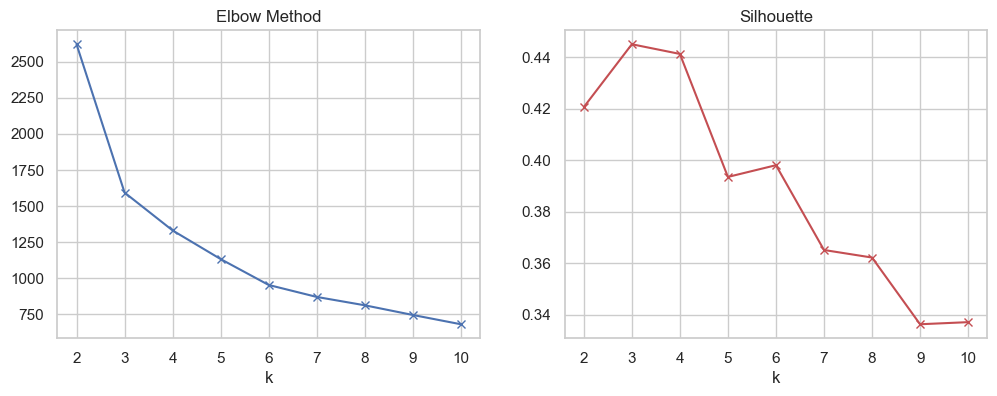

In [16]:
# For k = 2 to 10, fit KMeans(n_clusters=k, n_init=10, random_state=0) on X_scaled.
# Store each model's inertia_ in a list wcss and silhouette_score(X_scaled, model.labels_) in a list sil.
# Plot wcss and sil against k side by side (as in the customer segmentation notebook).
wcss, sil = [], []
K = range(2, 11)
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K, wcss, 'bx-'); axes[0].set_xlabel('k'); axes[0].set_title('Elbow Method')
axes[1].plot(K, sil, 'rx-'); axes[1].set_xlabel('k'); axes[1].set_title('Silhouette')
plt.show()

In [17]:
# Without labels, we interpret the clusters through their centres. Put the k = 4 centres (kmeans.cluster_centers_)
# back into the original units with scaler.inverse_transform, as a DataFrame with the feature names as columns.
centres = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=df_features.columns)
centres.round(3)

,mean,median,std,min,max,neg_share
0,0.028,0.131,0.903,-3.454,4.864,0.288
1,0.888,0.294,1.551,-0.380,9.945,0.029
2,0.323,0.187,0.367,-0.013,3.476,0.008
3,1.499,0.993,1.512,0.119,9.020,0.000


✏️ **Q5.** Which k would you choose from these two plots alone, and why? Then, using the centres only (no labels), name the four clusters as you would report them to the DSO.

**Answer:** Neither plot is decisive: the WCSS curve bends smoothly and the silhouette peaks at k = 3 (0.445) with k = 4 almost equal (0.441); at k = 3, k-means finds PV homes, electrified homes and homes without DER, which are the three groups these features can really tell apart. From the centres at k = 4: **PV homes** (min −3.5 kWh, export in 29 % of hours), **no DER** (mean 0.3 kWh, max 3.5 kWh), **electrified homes with high peaks** (mean 0.9 kWh, max 9.9 kWh) and **large consumers with a high base load** (mean 1.5 kWh, median 1.0 kWh). The last two are both mostly `EV_HP`, split in two, so `EV_PV` gets no cluster of its own.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 5. Another model: Gaussian Mixture (GMM)

</div>

*Together: fill in the blanks as we go.*

Sections 3 and 4 showed the same failure twice: k-means splits `EV_HP` and merges `PV` with `EV_PV`. This follows from how k-means assigns points: each meter joins its nearest centre, which implicitly assumes round clusters of similar spread. After scaling, `EV_HP` is two to four times as spread out as `Nothing` depending on the feature, so a single centre cannot hold it. A Gaussian Mixture Model fits one Gaussian per cluster with its own covariance, so clusters can be elongated and of different sizes. Same features, same k: only the model changes.

In [18]:
gmm = GaussianMixture(n_components=4, n_init=3, random_state=0).fit(X_scaled)
y_gmm = gmm.predict(X_scaled)
pred = pd.crosstab(labels, y_gmm).idxmax().loc[y_gmm].values
print('ARI GMM:', round(adjusted_rand_score(labels, y_gmm), 3))
print('Accuracy:', round(accuracy_score(labels, pred), 3), '| macro-F1:', round(f1_score(labels, pred, average='macro'), 3))
pd.crosstab(labels, y_gmm)

ARI GMM: 0.725
Accuracy: 0.876 | macro-F1: 0.875


col_0,0,1,2,3
Label,,,,
EV_HP,0,4,171,0
EV_PV,128,0,0,47
Nothing,0,162,13,0
PV,23,0,0,152


✏️ **Q6.** With the same features, the ARI goes from 0.50 (k-means) to 0.73 (GMM). Compare the two crosstabs: which classes does the GMM separate that k-means could not, and what property of those classes explains it?

**Answer:** The GMM keeps `EV_HP` in one cluster (171 of 175 meters) and gives `EV_PV` a cluster of its own (128 meters), although 47 `EV_PV` meters still sit with `PV`. Both gains come from differences in spread, not only in position: `EV_HP` varies far more than the other classes, and `EV_PV` is more spread out than `PV` in `max` (EV charging peaks vary from house to house). k-means only sees distances to centres; the GMM's covariances capture the spread.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 6. Visualisation: PCA and t-SNE

</div>

*PCA: you write the code, then we go over the solution together. t-SNE: together, fill in the blanks as we go.*

PCA gives a second, label-free view of the same meters. We apply it to both representations: the average daily profiles of Section 1, whose loadings can be read hour by hour, and the six features of Section 3 on which the GMM was fitted. As in the slides, we standardise first. For the six features this is required (kWh and shares on different scales); for the profiles all columns are kWh, and standardising changes little because every hour has a similar spread across meters (0.5 to 1.0 kWh).

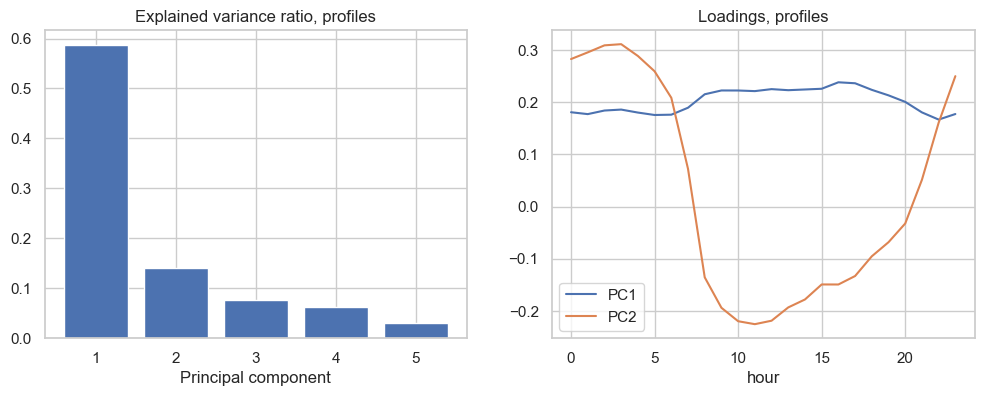

In [19]:
# Standardise df_profiles with StandardScaler into scaled_data and fit PCA(n_components=5) on it (pca_profiles).
# Plot side by side: the explained variance ratio of the 5 components (bar chart) and the loadings of PC1 and PC2 against the hour
# (pca_profiles.components_[0] and [1]).
scaled_data = StandardScaler().fit_transform(df_profiles)
pca_profiles = PCA(n_components=5).fit(scaled_data)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 6), pca_profiles.explained_variance_ratio_)
axes[0].set_xlabel('Principal component'); axes[0].set_title('Explained variance ratio, profiles')
axes[1].plot(pca_profiles.components_[0], label='PC1'); axes[1].plot(pca_profiles.components_[1], label='PC2')
axes[1].set_xlabel('hour'); axes[1].set_title('Loadings, profiles'); axes[1].legend()
plt.show()

In [20]:
# Fit PCA() on X_scaled (pca_features) and store the projected meters in results_pca (pca_features.transform).
# Print the explained variance ratio and show the PC1 and PC2 loadings of the six features as a DataFrame.
pca_features = PCA().fit(X_scaled)
results_pca = pca_features.transform(X_scaled)
print('Explained variance ratio, features:', pca_features.explained_variance_ratio_.round(2))
pd.DataFrame(pca_features.components_[:2].T, index=df_features.columns, columns=['PC1', 'PC2']).round(2)

Explained variance ratio, features: [0.54 0.3  0.1  0.03 0.02 0.01]


,PC1,PC2
mean,0.54,0.00
median,0.44,0.02
std,0.31,0.58
min,0.36,-0.51
max,0.38,0.45
neg_share,-0.38,0.45


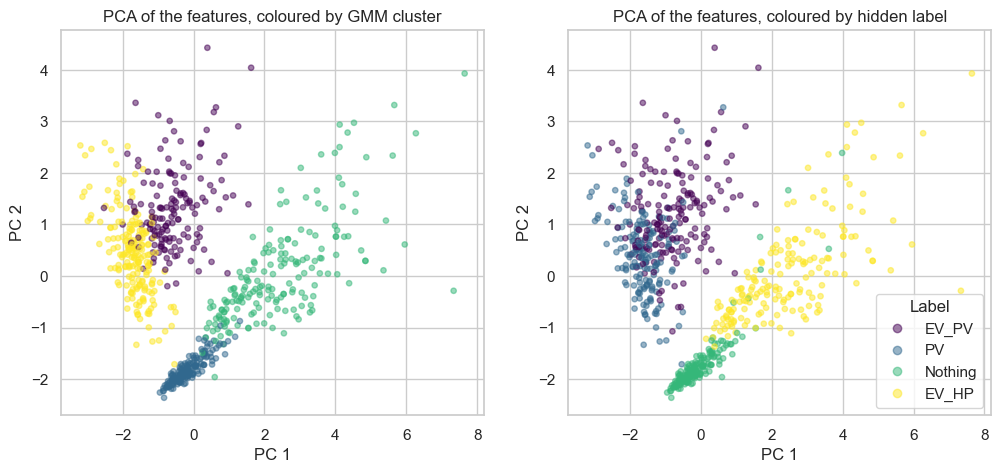

In [21]:
labels_encoded, label_names = pd.factorize(labels)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(results_pca[:, 0], results_pca[:, 1], c=y_gmm, s=15, alpha=0.5, cmap='viridis')
axes[0].set_title('PCA of the features, coloured by GMM cluster')
sc = axes[1].scatter(results_pca[:, 0], results_pca[:, 1], c=labels_encoded, s=15, alpha=0.5, cmap='viridis')
axes[1].legend(sc.legend_elements()[0], label_names, title='Label'); axes[1].set_title('PCA of the features, coloured by hidden label')
for ax in axes:
    ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')
plt.show()

✏️ **Q7.** Read the loadings of both PCAs. What does each first and second component represent physically, and on what do the two views agree?

**Answer:** Profiles: PC1 (59 %) loads positively on every hour, so it measures the consumption level; PC2 (14 %) is positive at night and negative at midday, contrasting night load (EV, heat pump) with the PV dip. Features: PC1 (54 %) again measures level (`mean`, `median`, `max` up, `neg_share` down), and PC2 (30 %) combines high `std`, `max` and `neg_share` with a low `min`, i.e. PV export together with large peaks. Both views agree that size is the main axis of variation, the information that normalising removed in Section 1, and that PV is the second.

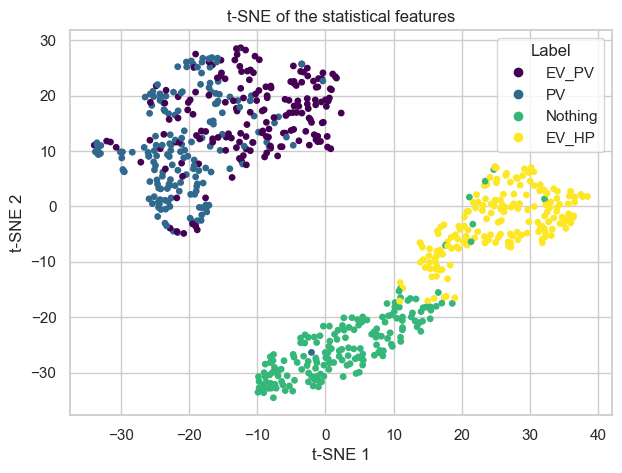

In [22]:
X_embedded = TSNE(n_components=2, perplexity=30, init='pca', random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
sc = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=labels_encoded, s=15, cmap='viridis')
plt.legend(sc.legend_elements()[0], label_names, title='Label')
plt.title('t-SNE of the statistical features'); plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.show()

> **Caution:** t-SNE is for visualisation only. The map agrees with the crosstabs: `PV` and `EV_PV` share one region, while `Nothing` and `EV_HP` form a second one in which each class keeps its own end. But t-SNE only preserves neighbourhoods: the distances between islands and their sizes carry no meaning, and the picture changes with the perplexity and the random seed. Use it to look at the data, not to cluster it or to measure how separable the classes are.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

## 7. Conclusions

</div>

| Approach | Features | Model | ARI | Accuracy | Macro-F1 |
|---|---|---|---|---|---|
| Average daily profiles | 24 hours (kWh) | k-means | 0.35 | 0.63 | 0.55 |
| Average daily profiles | 24 hours (shape) | k-means | 0.34 | 0.62 | 0.62 |
| Average daily profiles | 24 hours (kWh) | k-means, DTW ±2 h | 0.42 | 0.65 | 0.56 |
| Statistics | mean, median, std | k-means | 0.40 | 0.64 | 0.55 |
| Statistics + domain hints | + min, max, neg_share | k-means | 0.50 | 0.68 | 0.59 |
| Statistics + domain hints | + min, max, neg_share | GMM | 0.73 | 0.88 | 0.88 |

Read the table from top to bottom. Normalising the profiles made the ARI slightly worse because size carries information in this data, DTW helped only for one of three random seeds, and replacing 24 hourly values by three yearly statistics barely changed it. The ARI only moved when the features started to reflect physics: `min` and `neg_share` respond to export and `max` to large loads. The last and largest gain came from the model rather than the features: a nearest-centre rule cannot hold a class as spread out as `EV_HP`, and a GMM can.

None of the label-free tools would have told us this. The elbow and silhouette did not point to the four classes, and PCA and t-SNE showed structure without measuring it. The ARI could, only because the labels were set aside; a DSO without labels is left with the cluster centres and the judgement of whether they make physical sense.

<div style="background-color: #f0f0f0; padding: 25px; border-radius: 5px; font-weight: bold; margin-top: 25px;">

### Going further: more advanced features

</div>

The `PV` / `EV_PV` confusion survives every step above. The paper combines two families of features that go further than yearly statistics:

* **Domain-oriented**: one feature per DER, built so that the other DERs cannot mask it.
  * PV: `export_share` = exported / (imported + exported) energy.
  * EV: share of days with at least one hour above 3 kWh, or with ≥ 2 consecutive night hours above 3 kWh (a charging block); at night, PV cannot hide the charging.
  * Heat pump: winter / summer import using night hours only, so that PV does not inflate the ratio.
  * Keep at most one size feature (e.g. mean import): with several, k-means counts size several times.
* **Domain-agnostic** (time-series features, as in the paper): autocorrelation at lag 1 h, 24 h, sum of the first 10 lags (`acf1`, `acf10`), seasonal strength, entropy, trend. Libraries: [tsfeatures](https://github.com/Nixtla/tsfeatures), [IFEEL](https://maomaohu.net/software/ifeel/).